# Final Integrated Temporal Output

This notebook combines the outputs of Function 1 and Function 2 into a compact PP1-ready C3 result table.

## Function 1
- Product × Aspect × Quarter
- Bayesian smoothing
- uncertainty
- EWMA trend
- PELT change point

## Function 2
- negative-rate growth
- persistence
- emerging-status detection
- issue risk
- issue confidence

## Important

This notebook is still using **synthetic dummy data**.

Any values generated here are for implementation / demonstration only and must not be reported as final research results.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

WORKSPACE = Path.cwd()
if WORKSPACE.name == "notebooks":
    COMPONENT_ROOT = WORKSPACE.parent
elif (WORKSPACE / "data" / "processed").exists():
    COMPONENT_ROOT = WORKSPACE
else:
    COMPONENT_ROOT = WORKSPACE / "component_3"

INPUT = COMPONENT_ROOT / "data" / "processed" / "paq_with_emerging_status.csv"

OUTPUT_DIR = COMPONENT_ROOT / "data" / "processed"
TABLE_DIR = COMPONENT_ROOT / "outputs" / "tables"
FIGURE_DIR = COMPONENT_ROOT / "outputs" / "figures"

for p in [OUTPUT_DIR, TABLE_DIR, FIGURE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

ASPECT_OUTPUT = OUTPUT_DIR / "pp1_c3_latest_aspect_output.csv"
PRODUCT_OUTPUT = OUTPUT_DIR / "pp1_c3_product_summary.csv"


## 1. Load and validate the integrated C3 output


In [2]:
df = pd.read_csv(INPUT)

required = [
    "parent_asin",
    "aspect",
    "quarter",
    "review_count",
    "smoothed_sentiment",
    "ci_lower",
    "ci_upper",
    "temporal_confidence_dev",
    "trend",
    "latest_change_point",
    "emerging_status",
    "emerging_label",
    "issue_risk",
    "issue_confidence_dev",
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["quarter_period"] = pd.PeriodIndex(
    df["quarter"],
    freq="Q"
)

df = (
    df
    .sort_values(
        ["parent_asin", "aspect", "quarter_period"]
    )
    .reset_index(drop=True)
)

print("Rows:", len(df))
print("Products:", df["parent_asin"].nunique())
print(
    "Product-aspect series:",
    df[["parent_asin", "aspect"]].drop_duplicates().shape[0]
)


Rows: 550
Products: 10
Product-aspect series: 50


## 2. Take the latest quarter for each Product × Aspect


In [3]:
latest = (
    df
    .sort_values("quarter_period")
    .groupby(
        ["parent_asin", "aspect"],
        as_index=False
    )
    .tail(1)
    .copy()
)

print("Latest rows:", len(latest))
display(latest.head())


Latest rows: 50


,parent_asin,aspect,quarter,review_count,mean_sentiment,median_sentiment,positive_rate,neutral_rate,negative_rate,avg_confidence,...,above_history,persistence_2q,quarters_since_change,recent_change_evidence,emerging_status,emerging_label,issue_risk,issue_confidence_dev,issue_confidence_label_dev,quarter_period
329,B019BX7F86,thermal,2023Q3,11,-0.2346,-0.2311,0.0000,0.4545,0.5455,0.7210,...,1,True,2.0,True,2,New / rapidly increasing issue,High,0.7713,Medium,2023Q3
340,B01K1IO3QW,battery,2023Q3,11,0.0778,0.1749,0.3636,0.4545,0.1818,0.7599,...,1,True,NaN,False,0,No meaningful issue,Low,0.7655,Medium,2023Q3
384,B01K1IO3QW,thermal,2023Q3,9,-0.4896,-0.5146,0.0000,0.0000,1.0000,0.7933,...,1,True,3.0,False,2,New / rapidly increasing issue,High,0.7632,Medium,2023Q3
395,B01MPXRXR0,battery,2023Q3,12,-0.4892,-0.4902,0.0000,0.1667,0.8333,0.7920,...,1,True,3.0,False,2,New / rapidly increasing issue,High,0.7870,Medium,2023Q3
362,B01K1IO3QW,keyboard,2023Q3,9,0.3807,0.4173,0.6667,0.3333,0.0000,0.7745,...,0,False,NaN,False,0,No meaningful issue,Low,0.6474,Medium,2023Q3


## 3. Create a development 0–100 review-perceived quality score

The current smoothed sentiment is in the range `[-1, 1]`.

For PP1 display only, it is linearly mapped to `[0, 100]`:

`quality = ((smoothed_sentiment + 1) / 2) × 100`

This is a **display transformation**, not the final research quality formula.


In [4]:
latest["review_perceived_quality_dev"] = (
    (
        latest["smoothed_sentiment"] + 1
    ) / 2 * 100
).clip(0, 100)

latest["quality_ci_lower_dev"] = (
    (
        latest["ci_lower"] + 1
    ) / 2 * 100
).clip(0, 100)

latest["quality_ci_upper_dev"] = (
    (
        latest["ci_upper"] + 1
    ) / 2 * 100
).clip(0, 100)

for c in [
    "review_perceived_quality_dev",
    "quality_ci_lower_dev",
    "quality_ci_upper_dev",
]:
    latest[c] = latest[c].round(1)


## 4. Build the PP1 C3 aspect-level output table

This is the most useful table for the demo and for later C4 integration.

It reports:
- latest review-perceived quality
- trend direction
- latest detected change point
- emerging issue status
- issue risk
- confidence


In [5]:
aspect_output = latest[[
    "parent_asin",
    "aspect",
    "quarter",
    "review_count",
    "review_perceived_quality_dev",
    "quality_ci_lower_dev",
    "quality_ci_upper_dev",
    "trend",
    "latest_change_point",
    "emerging_status",
    "emerging_label",
    "issue_risk",
    "issue_confidence_dev",
]].copy()

aspect_output = aspect_output.rename(
    columns={
        "quarter": "latest_quarter",
        "latest_change_point": "change_point",
        "issue_confidence_dev": "confidence_dev",
    }
)

aspect_output["confidence_dev"] = (
    aspect_output["confidence_dev"]
    .round(3)
)

aspect_output.to_csv(
    ASPECT_OUTPUT,
    index=False
)

display(
    aspect_output.sort_values(
        ["emerging_status", "issue_risk", "confidence_dev"],
        ascending=[False, True, False]
    )
)

print("Saved:", ASPECT_OUTPUT)


,parent_asin,aspect,latest_quarter,review_count,review_perceived_quality_dev,quality_ci_lower_dev,quality_ci_upper_dev,trend,change_point,emerging_status,emerging_label,issue_risk,confidence_dev
395,B01MPXRXR0,battery,2023Q3,12,36.5,30.9,42.4,Declining,2022Q4,2,New / rapidly increasing issue,High,0.787
329,B019BX7F86,thermal,2023Q3,11,45.9,42.1,49.7,Declining,2023Q1,2,New / rapidly increasing issue,High,0.771
384,B01K1IO3QW,thermal,2023Q3,9,35.5,32.1,39.5,Declining,2022Q4,2,New / rapidly increasing issue,High,0.763
153,B00L49X8E6,performance,2023Q3,11,58.4,50.7,66.0,Stable,NaN,2,New / rapidly increasing issue,Medium,0.764
263,B00TW47DSW,performance,2023Q3,8,65.1,54.5,73.0,Stable,NaN,1,Existing issue,Medium,0.628
351,B01K1IO3QW,display,2023Q3,11,62.9,57.7,67.3,Stable,NaN,0,No meaningful issue,Low,0.775
340,B01K1IO3QW,battery,2023Q3,11,57.1,49.7,64.3,Stable,NaN,0,No meaningful issue,Low,0.766
318,B019BX7F86,performance,2023Q3,10,63.2,57.9,68.7,Stable,NaN,0,No meaningful issue,Low,0.760
241,B00TW47DSW,camera,2023Q3,8,52.6,49.7,56.5,Stable,NaN,0,No meaningful issue,Low,0.727
197,B00NOSVK54,display,2023Q3,14,82.8,78.1,87.2,Stable,2022Q2,0,No meaningful issue,Low,0.721


Saved: c:\Users\victus\Desktop\Repository\J26-DS-349\component_3\data\processed\pp1_c3_latest_aspect_output.csv


## 5. Build a product-level PP1 summary

This provides a compact product view for the presentation.

Development-only aggregation:
- mean latest aspect quality
- number of declining aspects
- number of emerging aspects
- number of existing-issue aspects
- maximum issue risk
- average issue confidence

This is not a final ranking formula.


In [6]:
risk_rank = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

latest["_risk_rank"] = (
    latest["issue_risk"]
    .map(risk_rank)
    .fillna(0)
)

def summarize_product(group):
    max_risk_value = int(group["_risk_rank"].max())

    reverse_risk = {
        0: "Low",
        1: "Medium",
        2: "High"
    }

    return pd.Series({
        "latest_quarter": group["quarter"].max(),
        "mean_aspect_quality_dev": round(
            group["review_perceived_quality_dev"].mean(),
            1
        ),
        "declining_aspects": int(
            (group["trend"] == "Declining").sum()
        ),
        "improving_aspects": int(
            (group["trend"] == "Improving").sum()
        ),
        "emerging_aspects": int(
            (group["emerging_status"] == 2).sum()
        ),
        "existing_issue_aspects": int(
            (group["emerging_status"] == 1).sum()
        ),
        "maximum_issue_risk": reverse_risk[max_risk_value],
        "mean_issue_confidence_dev": round(
            group["issue_confidence_dev"].mean(),
            3
        ),
    })

product_summary = (
    latest
    .groupby("parent_asin")
    .apply(summarize_product)
    .reset_index()
)

product_summary.to_csv(
    PRODUCT_OUTPUT,
    index=False
)

display(
    product_summary.sort_values(
        ["emerging_aspects", "declining_aspects"],
        ascending=[False, False]
    )
)

print("Saved:", PRODUCT_OUTPUT)


,parent_asin,latest_quarter,mean_aspect_quality_dev,declining_aspects,improving_aspects,emerging_aspects,existing_issue_aspects,maximum_issue_risk,mean_issue_confidence_dev
5,B019BX7F86,2023Q3,61.6,1,0,1,0,High,0.704
6,B01K1IO3QW,2023Q3,58.8,1,0,1,0,High,0.730
7,B01MPXRXR0,2023Q3,60.6,1,0,1,0,High,0.692
2,B00L49X8E6,2023Q3,64.2,0,0,1,0,Medium,0.682
8,B07GM2J11Q,2023Q3,65.8,1,0,0,0,Low,0.673
0,B00FFJ0HUE,2023Q3,67.6,0,0,0,0,Low,0.555
1,B00KB7O49K,2023Q3,69.0,0,0,0,0,Low,0.545
3,B00NOSVK54,2023Q3,68.2,0,0,0,0,Low,0.687
4,B00TW47DSW,2023Q3,61.1,0,0,0,1,Medium,0.676
9,B0C2ZMJW53,2023Q3,66.7,0,0,0,0,Low,0.674


Saved: c:\Users\victus\Desktop\Repository\J26-DS-349\component_3\data\processed\pp1_c3_product_summary.csv


## 6. Show only current emerging / existing issues

This table is useful for the PP1 live demo.


In [7]:
issue_cases = aspect_output[
    aspect_output["emerging_status"] > 0
].copy()

issue_cases = issue_cases.sort_values(
    ["emerging_status", "confidence_dev"],
    ascending=[False, False]
)

issue_cases.to_csv(
    TABLE_DIR / "pp1_current_issue_cases.csv",
    index=False
)

display(issue_cases)


,parent_asin,aspect,latest_quarter,review_count,review_perceived_quality_dev,quality_ci_lower_dev,quality_ci_upper_dev,trend,change_point,emerging_status,emerging_label,issue_risk,confidence_dev
395,B01MPXRXR0,battery,2023Q3,12,36.5,30.9,42.4,Declining,2022Q4,2,New / rapidly increasing issue,High,0.787
329,B019BX7F86,thermal,2023Q3,11,45.9,42.1,49.7,Declining,2023Q1,2,New / rapidly increasing issue,High,0.771
153,B00L49X8E6,performance,2023Q3,11,58.4,50.7,66.0,Stable,NaN,2,New / rapidly increasing issue,Medium,0.764
384,B01K1IO3QW,thermal,2023Q3,9,35.5,32.1,39.5,Declining,2022Q4,2,New / rapidly increasing issue,High,0.763
263,B00TW47DSW,performance,2023Q3,8,65.1,54.5,73.0,Stable,NaN,1,Existing issue,Medium,0.628


## 7. Plot product-level emerging / declining aspect counts


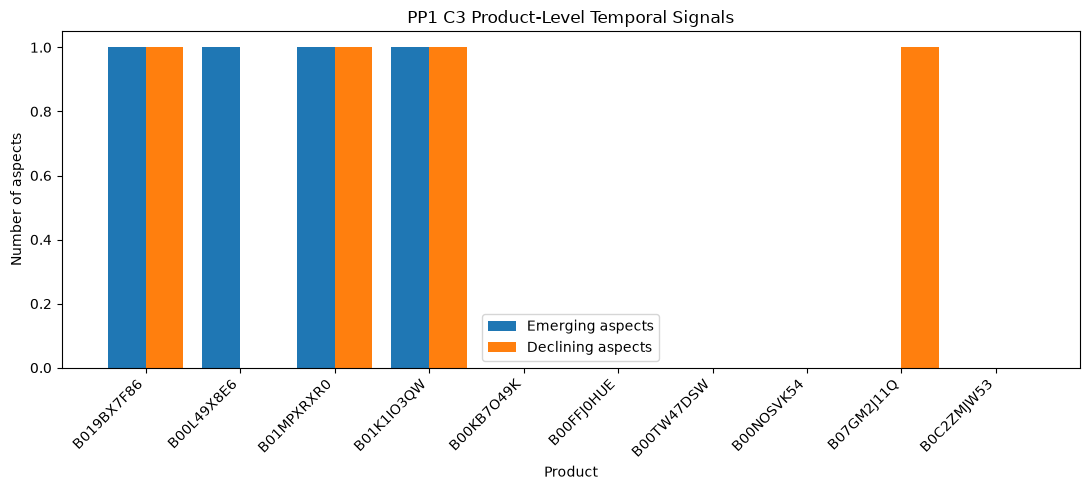

In [8]:
plot_df = product_summary.sort_values(
    "emerging_aspects",
    ascending=False
)

x = np.arange(len(plot_df))

plt.figure(figsize=(11, 5))

plt.bar(
    x - 0.2,
    plot_df["emerging_aspects"],
    width=0.4,
    label="Emerging aspects"
)

plt.bar(
    x + 0.2,
    plot_df["declining_aspects"],
    width=0.4,
    label="Declining aspects"
)

plt.xticks(
    x,
    plot_df["parent_asin"],
    rotation=45,
    ha="right"
)

plt.ylabel("Number of aspects")
plt.xlabel("Product")
plt.title("PP1 C3 Product-Level Temporal Signals")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "pp1_product_temporal_signals.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()
